# Alpha/beta complex — results

Step 2 of the alpha/beta analysis: run the alpha/beta complex simulation (feedforward
proximal + feedback distal bursty drives, 600 trials) via
`step1_alpha_beta_complex_simulation.py`, then reproduce the figures — the model
alpha/beta summary, the laminar LFP/CSD, and the comparison to human MEG data
(`data/spectralevents_data/`).

Reproduces Figure 9 in the manuscript.

Author: Katharina Duecker <katharina.duecker@gmail.com>

In [22]:
# RUN ONLY IF WORKING ON OSCAR
import os

# Use conda's newer libstdc++ instead of the system one
conda_lib = os.path.expanduser("~/.conda/envs/hnn-core-env/lib")
ld_path = os.environ.get("LD_LIBRARY_PATH", "")
os.environ["LD_LIBRARY_PATH"] = f"{conda_lib}:{ld_path}"

# UCX settings (from before)
os.environ["UCX_TLS"] = "tcp,self,sm"
os.environ["UCX_NET_DEVICES"] = "all"


# MPI paths
mpi_bin = "/oscar/rt/sw/external/hpcx-mpi/2.25.1/bin"
mpi_lib = "/oscar/rt/sw/external/hpcx-mpi/2.25.1/lib"
if mpi_bin not in os.environ["PATH"]:
    os.environ["PATH"] = f"{mpi_bin}:{os.environ['PATH']}"
if mpi_lib not in ld_path:
    os.environ["LD_LIBRARY_PATH"] = f"{mpi_lib}:{os.environ['LD_LIBRARY_PATH']}"

import sys
# Add MPI bin directory to PATH
mpi_bin = "/oscar/rt/sw/external/hpcx-mpi/2.25.1/bin"
if mpi_bin not in os.environ["PATH"]:
    os.environ["PATH"] = f"{mpi_bin}:{os.environ['PATH']}"

print("Updated PATH to include MPI")
print("MPI location:", mpi_bin)

import os
print("PATH:", os.environ.get('PATH', 'NOT SET'))
print("Which mpiexec:")
import subprocess
result = subprocess.run(['which', 'mpiexec'], capture_output=True, text=True)
print(result.stdout if result.returncode == 0 else "mpiexec not found")

Updated PATH to include MPI
MPI location: /oscar/rt/sw/external/hpcx-mpi/2.25.1/bin
PATH: /oscar/rt/sw/external/hpcx-mpi/2.25.1/bin:/users/kduecker/.conda/envs/hnn-core-env/bin:/oscar/rt/9.6/25/x86_64_v3/code-server-4.96.4-2mbqypo7726gva5cbeogfppy2doijdhq/lib/vscode/bin/remote-cli:/users/kduecker/bin:/oscar/runtime/bin:/oscar/rt/9.6/25/spack/x86_64_v3/code-server-4.96.4-2mbqypo7726gva5cbeogfppy2doijdhq/bin:/users/kduecker/.conda/envs/hnn-core-env/bin:/oscar/rt/9.6/25/x86_64_v3/miniforge3-25.3.0-3-a6hhdjzejtacz63sugjqnvgosfqz63ul/condabin:/users/kduecker/bin:/usr/local/bin:/usr/bin:/usr/local/sbin:/usr/sbin:/usr/lpp/mmfs/bin:/usr/lpp/mmfs/sbin:/users/kduecker/bin
Which mpiexec:
/oscar/rt/sw/external/hpcx-mpi/2.25.1/bin/mpiexec



In [2]:
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from step1_alpha_beta_complex_simulation import (compute_symmetry_index, alpha_beta_ratio, compute_tfr, compute_psd)

import random
import pandas as pd
import os
import os.path as op
import numpy as np
import pickle

import scipy.io as sio

from hnn_core import duecker_ET_model, simulate_dipole, MPIBackend

from hnn_tuning import DATA, results_dir
from hnn_tuning.model_data_comparison import load_ephys_csv

# bundled human MEG data + regenerable figure output
data_pth = str(DATA / 'spectralevents_data')
pathfig = results_dir('network_sim', 'alpha_beta')
from hnn_tuning import NETWORK_SIM
main_pth = str(NETWORK_SIM / 'alpha_beta')
out_pth = op.join(main_pth, 'sim_results')

import time
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42
n_procs = 3


--No graphics will be displayed.


## Model alpha/beta complex

Simulate the network (600 trials) and summarise the dipole: waveform, Morlet TFR, PSD, and the distributions of the alpha/beta ratio and waveform symmetry index.

In [3]:
from step1_alpha_beta_complex_simulation import run_alpha_beta_complex_simulations, sim_analysis_params_default

# params = sim_analysis_params_default()
# params['n_procs'] = n_procs
# params['prox_seed'] = 544
# params['dist_seed'] = 476

# # run the alpha/beta complex simulation in-notebook (600 trials)
# dpl, net = run_alpha_beta_complex_simulations(params, n_trials=600)

# # per-trial spectral summaries (same measures as step1's run_main)
# ab_ratio, alpha_power, beta_power, prob_overlap = alpha_beta_ratio(dpl)
# symmetry_index = [compute_symmetry_index(d, lowcut=7, highcut=29)[0] for d in dpl]
# sim = pd.DataFrame({
#     'alpha_beta_ratio': list(ab_ratio),
#     'prob_overlap': prob_overlap,
#     'symmetry_index': symmetry_index,
# })

run_idx = 1
params = sim_analysis_params_default()

# load the step1 outputs (run on the cluster) for this run_idx
sim = load_ephys_csv(op.join(out_pth, f'alpha_beta_complex_simulation_{run_idx}.csv'))
with open(op.join(out_pth, f'net_delay_{run_idx}.pkl'), 'rb') as fh:
    net = pickle.load(fh)
with open(op.join(out_pth, f'dpl_delay_{run_idx}.pkl'), 'rb') as fh:
    dpl = pickle.load(fh)


### Panel functions (shared by the model and data composites)

Each `plot_<panel>(ax, ...)` renders standalone below on the model run; `plot_model()` and `plot_data()` reuse them.

<Axes: ylabel='input spikes \n count'>

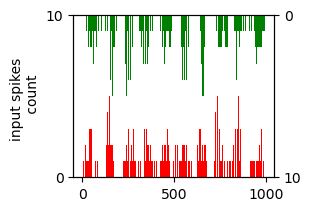

In [4]:
def plot_drive_hist(ax, net, bins):
    """Proximal (red) + distal (green, inverted twin) drive spike histograms. Model only."""
    spike_prox = np.array(net.cell_response.spike_times_by_type['prox'][0]).reshape(-1, 1)
    spike_dist = np.array(net.cell_response.spike_times_by_type['dist'][0]).reshape(-1, 1)
    ax.hist(spike_prox, bins, color='r')
    ax.set_ylim([0, 10]); ax.set_yticks([0, 10])
    ax_tw = ax.twinx()
    ax_tw.hist(spike_dist, bins, color='g')
    ax_tw.set_ylim([0, 10]); ax_tw.set_yticks([0, 10]); ax_tw.invert_yaxis()
    ax.set_ylabel('input spikes \n count')
    return ax


fig, ax = plt.subplots(figsize=(3, 2), constrained_layout=True)
plot_drive_hist(ax, net, np.arange(0, 1000, 5))

<Axes: xlabel='time (ms)', ylabel='dipole (nA m)'>

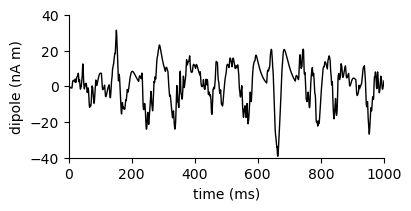

In [5]:
def plot_dipole(ax, times, y, color='k', xlim=None, ylim=None, yticks=None):
    """A single dipole waveform (aggregate)."""
    ax.plot(times, y, color=color, linewidth=1.)
    if xlim is not None: ax.set_xlim(xlim)
    if ylim is not None: ax.set_ylim(ylim)
    if yticks is not None: ax.set_yticks(yticks)
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
    ax.set_ylabel('dipole (nA m)'); ax.set_xlabel('time (ms)')
    return ax


fig, ax = plt.subplots(figsize=(4, 2), constrained_layout=True)
plot_dipole(ax, dpl[0].times, dpl[0].data['agg'], xlim=(0, 1000), ylim=(-40, 40), yticks=[-40, -20, 0, 20, 40])

(array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
        18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34,
        35, 36, 37, 38, 39]),
 array([[[1.77333984e+05, 1.77435094e+05, 1.77536172e+05, ...,
          2.49436016e+05, 2.49378844e+05, 2.49321578e+05],
         [1.51171768e+04, 1.51006465e+04, 1.50840527e+04, ...,
          1.05066570e+05, 1.05112500e+05, 1.05158164e+05],
         [3.12275250e+05, 3.12992688e+05, 3.13710844e+05, ...,
          2.68584188e+05, 2.68158906e+05, 2.67734125e+05],
         ...,
         [5.29295062e+05, 5.45528312e+05, 5.62060000e+05, ...,
          2.30356725e+06, 2.21623175e+06, 2.13130125e+06],
         [4.71254844e+05, 4.86319688e+05, 5.01687312e+05, ...,
          1.91530212e+06, 1.84380488e+06, 1.77418412e+06],
         [4.08964781e+05, 4.22544219e+05, 4.36420938e+05, ...,
          1.59611425e+06, 1.53813462e+06, 1.48155338e+06]]],
       shape=(1, 39, 2001), dtype=float32))

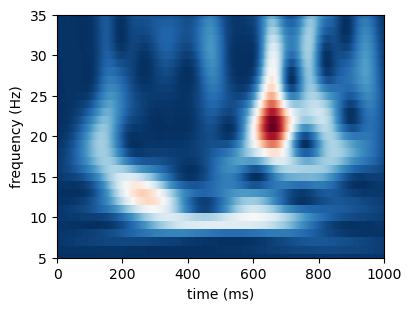

In [6]:
def plot_tfr(ax, dpl_single, times, cax=None, ylim=(5, 35)):
    """Morlet time-frequency representation of a single dipole; optional horizontal colorbar into `cax`."""
    f, tfr = compute_tfr([dpl_single])
    im = ax.pcolormesh(times, f, tfr[0], cmap='RdBu_r', vmin=0, vmax=tfr.max())
    ax.set_ylim(ylim); ax.set_ylabel('frequency (Hz)'); ax.set_xlabel('time (ms)')
    if cax is not None:
        cb = plt.colorbar(im, ax=cax, orientation='horizontal')
        cb.set_ticks([0, tfr.max()]); cb.set_label('power (nA m)^2')
        cax.set_axis_off()
    return f, tfr


fig, ax = plt.subplots(figsize=(4, 3), constrained_layout=True)
plot_tfr(ax, dpl[0], dpl[0].times)

<Axes: xlabel='frequency (Hz)', ylabel='power spectral density (nAm)^2Hz-1'>

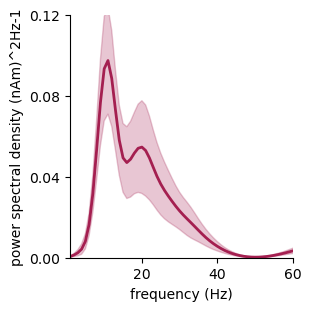

In [7]:
def plot_psd(ax, freq, psd_matrix, color, ylim, yticks, fill_color=None):
    """Mean +/- std power spectral density across trials/subjects."""
    fill_color = color if fill_color is None else fill_color
    m, s = psd_matrix.mean(axis=0), psd_matrix.std(axis=0)
    ax.plot(freq, m, color=color, linewidth=2)
    ax.fill_between(freq, m - s, m + s, color=fill_color, alpha=0.25)
    ax.set_xlim([1, 60]); ax.set_ylim(ylim); ax.set_yticks(yticks)
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
    ax.set_ylabel('power spectral density (nAm)^2Hz-1'); ax.set_xlabel('frequency (Hz)')
    return ax


f, psd = compute_psd(params, dpl)
fig, ax = plt.subplots(figsize=(3, 3), constrained_layout=True)
plot_psd(ax, f[0], psd, color='#a41f50', ylim=(0, 0.12), yticks=[0, 0.04, 0.08, 0.12])

<Axes: xlabel='alpha/beta ratio', ylabel='counts'>

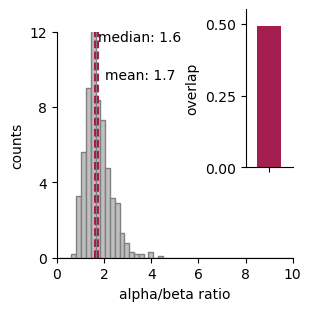

In [8]:
def plot_ab_ratio(ax, abr, overlap, color, ymax, yticks, yticklabels, text_y,
                  overlap_err=None, inset_ylim=(0, 0.55), inset_yticks=(0, 0.25, 0.5)):
    """Alpha/beta ratio histogram with mean/median lines and an overlap-probability inset."""
    ax.hist(abr, bins=np.linspace(0, 10, 50), facecolor=[0.75, 0.75, 0.75], edgecolor=[0.5, 0.5, 0.5])
    ax.vlines(np.mean(abr), ymin=0, ymax=ymax, color=color, linestyle='--')
    ax.vlines(np.median(abr), ymin=0, ymax=ymax, color=color, linestyle='--')
    ax.text(np.mean(abr) + 0.3, text_y[0], f'mean: {np.mean(abr):0.1f}', color='k')
    ax.text(np.median(abr) + 0.1, text_y[1], f'median: {np.median(abr):0.1f}', color='k')
    ax.set_xlabel('alpha/beta ratio'); ax.set_xlim([0, 10])
    ax.set_ylim([0, ymax]); ax.set_yticks(yticks); ax.set_yticklabels(yticklabels)
    ax.set_ylabel('counts')
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
    axin = ax.inset_axes([.8, 0.4, 0.2, .7])
    axin.bar(x=1, height=overlap, width=0.5, color=color, xerr=overlap_err)
    axin.set_xlim([0.5, 1.5]); axin.set_xticks([1]); axin.set_xticklabels([])
    axin.set_ylim(inset_ylim); axin.set_yticks(list(inset_yticks)); axin.set_ylabel('overlap')
    axin.spines['top'].set_visible(False); axin.spines['right'].set_visible(False)
    return ax


abr = np.concatenate(sim.alpha_beta_ratio.values)
fig, ax = plt.subplots(figsize=(3, 3), constrained_layout=True)
plot_ab_ratio(ax, abr, np.mean(sim.prob_overlap), color='#a41f50', ymax=1200,
              yticks=[0, 400, 800, 1200], yticklabels=[0, 4, 8, 12], text_y=(950, 1150))

<Axes: xlabel='symmetry index'>

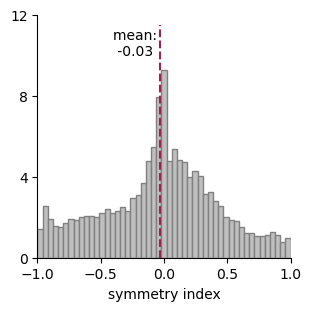

In [9]:
def plot_symmetry(ax, sid, color, yticks, yticklabels, text_y, vline_ymax, ylim=None):
    """Waveform symmetry-index histogram with the mean marked."""
    ax.hist(sid, bins=np.linspace(-1, 1, 50), facecolor=[0.75, 0.75, 0.75], edgecolor=[0.5, 0.5, 0.5])
    ax.vlines(np.mean(sid), ymin=0, ymax=vline_ymax, linewidth=1.5, color=color, linestyle='--')
    ax.text(-0.4, text_y, f'mean: \n {np.round(np.mean(sid), 2)}')
    ax.set_xlabel('symmetry index'); ax.set_xlim([-1, 1]); ax.set_xticks([-1, -0.5, 0, 0.5, 1])
    if ylim is not None: ax.set_ylim(ylim)
    ax.set_yticks(yticks); ax.set_yticklabels(yticklabels)
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
    return ax


sid = np.concatenate(sim.symmetry_index.values)
fig, ax = plt.subplots(figsize=(3, 3), constrained_layout=True)
plot_symmetry(ax, sid, color='#a41f50', yticks=np.arange(0, 1201, 400), yticklabels=[0, 4, 8, 12],
              text_y=1000, vline_ymax=1150, ylim=(0, 1200))

### Composite — model figure

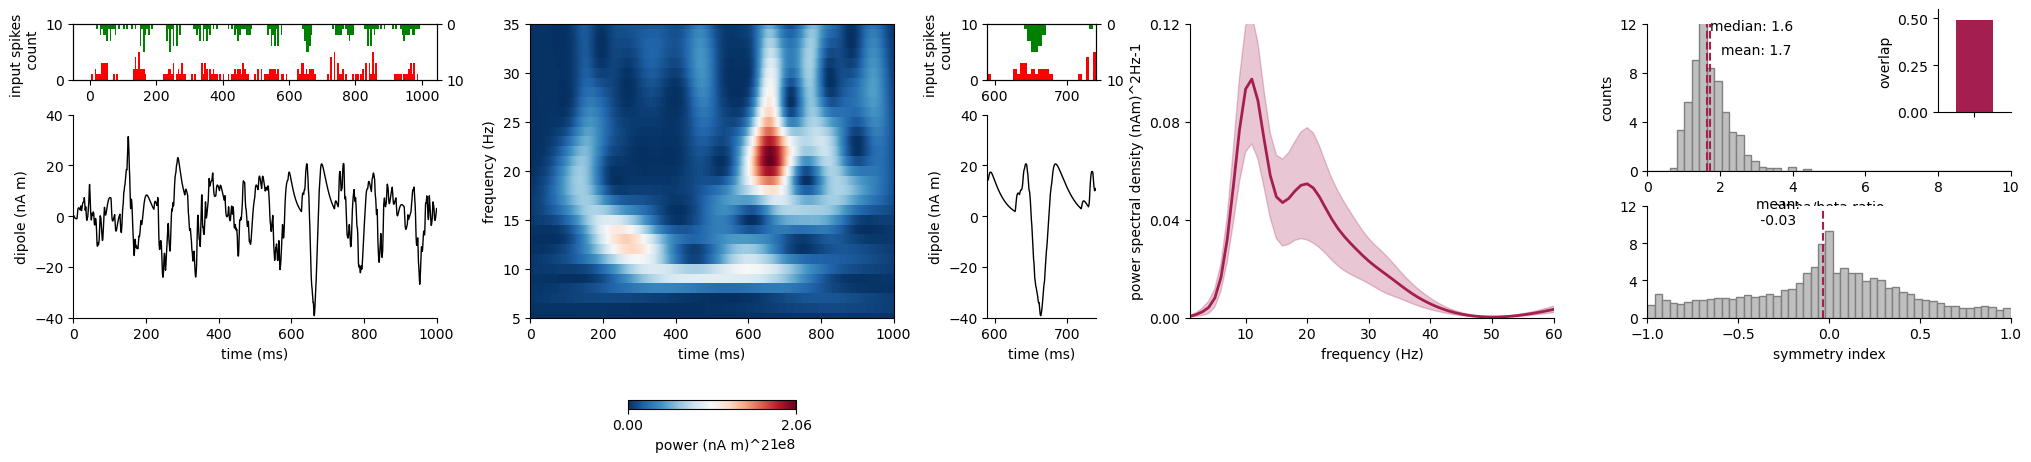

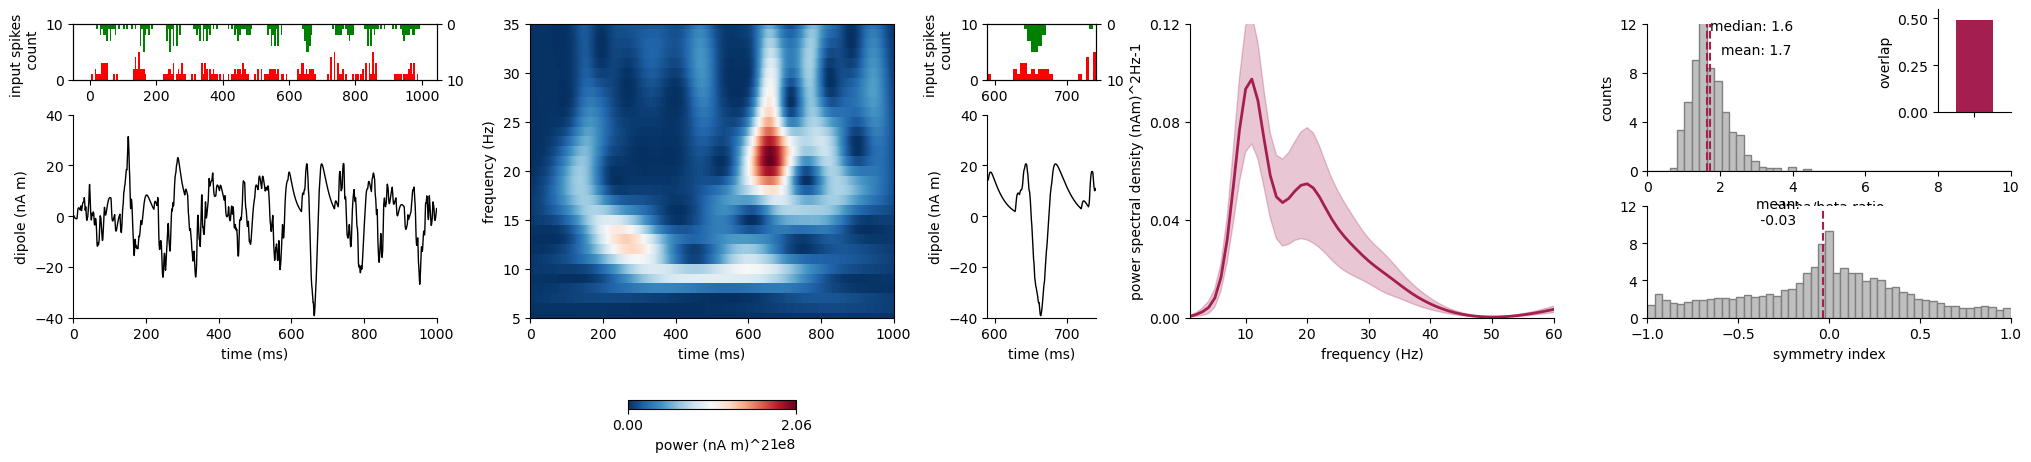

In [10]:
def plot_model():
    """Composite model alpha/beta figure (magenta) -> results/.../alpha_beta_sim."""
    fig = plt.figure(figsize=(25, 5))
    gs = GridSpec(4, 5, width_ratios=[1, 1, 0.3, 1, 1], height_ratios=[0.5, 0.5, 1, 0.5], wspace=.3, hspace=0.5)
    ax0 = fig.add_subplot(gs[0, 0]); ax1 = fig.add_subplot(gs[1:3, 0]); ax2 = fig.add_subplot(gs[:3, 1])
    ax3 = fig.add_subplot(gs[0, 2]); ax4 = fig.add_subplot(gs[1:3, 2]); ax5 = fig.add_subplot(gs[:3, 3])
    ax6 = fig.add_subplot(gs[:2, 4]); ax7 = fig.add_subplot(gs[2:3, 4]); cax = fig.add_subplot(gs[3, 1])
    color = '#a41f50'
    bins = np.arange(0, 1000, 5)

    plot_drive_hist(ax0, net, bins)
    plot_drive_hist(ax3, net, bins); ax3.set_xlim([590, 740])
    plot_dipole(ax1, dpl[0].times, dpl[0].data['agg'], xlim=(0, 1000), ylim=(-40, 40), yticks=[-40, -20, 0, 20, 40])
    plot_dipole(ax4, dpl[0].times, dpl[0].data['agg'], xlim=(590, 740), ylim=(-40, 40), yticks=[-40, -20, 0, 20, 40])
    plot_tfr(ax2, dpl[0], dpl[0].times, cax=cax)
    f, psd = compute_psd(params, dpl)
    plot_psd(ax5, f[0], psd, color=color, ylim=(0, 0.12), yticks=[0, 0.04, 0.08, 0.12])
    plot_ab_ratio(ax6, np.concatenate(sim.alpha_beta_ratio.values), np.mean(sim.prob_overlap), color=color,
                  ymax=1200, yticks=[0, 400, 800, 1200], yticklabels=[0, 4, 8, 12], text_y=(950, 1150))
    plot_symmetry(ax7, np.concatenate(sim.symmetry_index.values), color=color, yticks=np.arange(0, 1201, 400),
                  yticklabels=[0, 4, 8, 12], text_y=1000, vline_ymax=1150, ylim=(0, 1200))

    fig.savefig(op.join(pathfig, 'alpha_beta_sim.pdf'))
    fig.savefig(op.join(pathfig, 'alpha_beta_sim.png'))
    return fig


plot_model()

## Compare to source-localized MEG data

Data stored in `data/spectralevents-data`

In [11]:
# format as dipole class
class Dipole:

    def __init__(self, mat_data): 

        self.data = dict()
        self.data['agg'] = mat_data
        self.times = np.linspace(0, 1, mat_data.shape[0])
        self.nave = 1
        self.scale_applied = 1  # for visualisation
        self.sfreq = mat_data.shape[0]

In [12]:
# first subject
params['nfft']=None
data = sio.loadmat(f'{data_pth}/prestim_humandetection_600hzMEG_subject{1}.mat')
n_trials = len(data['prestim_raw_yes_no'])
subj1_dpls = [None]* n_trials
for trl in range(n_trials):
    data_dpl = Dipole(data['prestim_raw_yes_no'][trl]*1e9)          # convert to nA
    subj1_dpls[trl] = data_dpl

s_idx = np.zeros((n_trials,), dtype=object)
for i, dip in enumerate(subj1_dpls):
    s, ff = compute_symmetry_index(dip, lowcut=7, highcut=29, prominence=1e-8)
    s_idx[i] = s

ab_ratio, alpha_power, beta_power, prob_overlap = alpha_beta_ratio(subj1_dpls, dpl_type='data')

povl = np.zeros(10,)
povl[0] = prob_overlap

f, psd_subj = compute_psd(params, subj1_dpls)
psd_all_subj = np.zeros((10, f.shape[1]))
psd_all_subj[0] = psd_subj.mean(axis=0)

In [13]:
# Remaining 9 subjects
for si in np.arange(2,11):
    data = sio.loadmat(f'{data_pth}/prestim_humandetection_600hzMEG_subject{si}.mat')
    n_trials = len(data['prestim_raw_yes_no'])
    subj_dpls = [None]* n_trials
    for trl in range(n_trials):
        data_dpl = Dipole(data['prestim_raw_yes_no'][trl]*1e9)
        subj_dpls[trl] = data_dpl

    sid = np.zeros((n_trials,), dtype=object)
    for i, dip in enumerate(subj_dpls):
        s, ff = compute_symmetry_index(dip, lowcut=7, highcut=29, prominence=1e-8)
        sid[i] = s

    s_idx = np.concatenate((s_idx,sid))

    abr, _, _, prob_overlap = alpha_beta_ratio(subj_dpls, dpl_type='data')

    ab_ratio = np.concatenate((ab_ratio, abr))
    povl[int(si-1)] = prob_overlap

    _, psd_subj = compute_psd(params, subj_dpls)

    psd_all_subj[si-1] = psd_subj.mean(axis=0)

### Composite — data figure

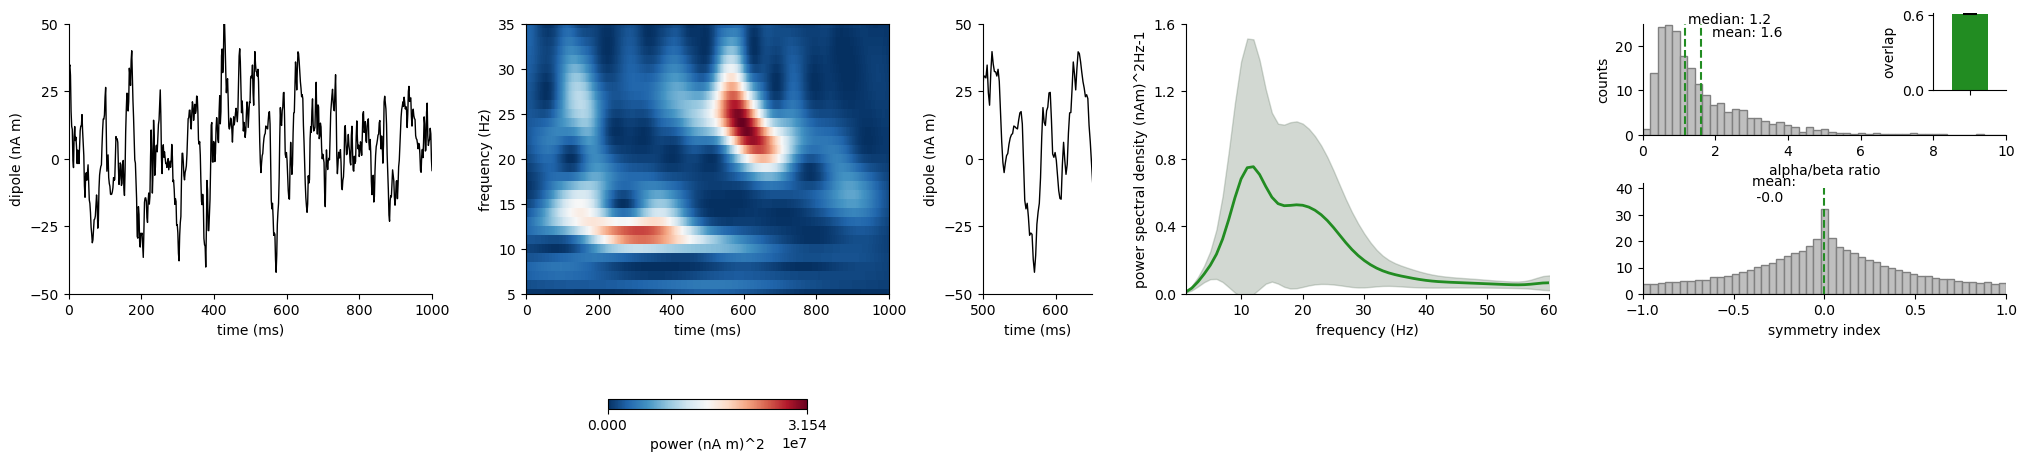

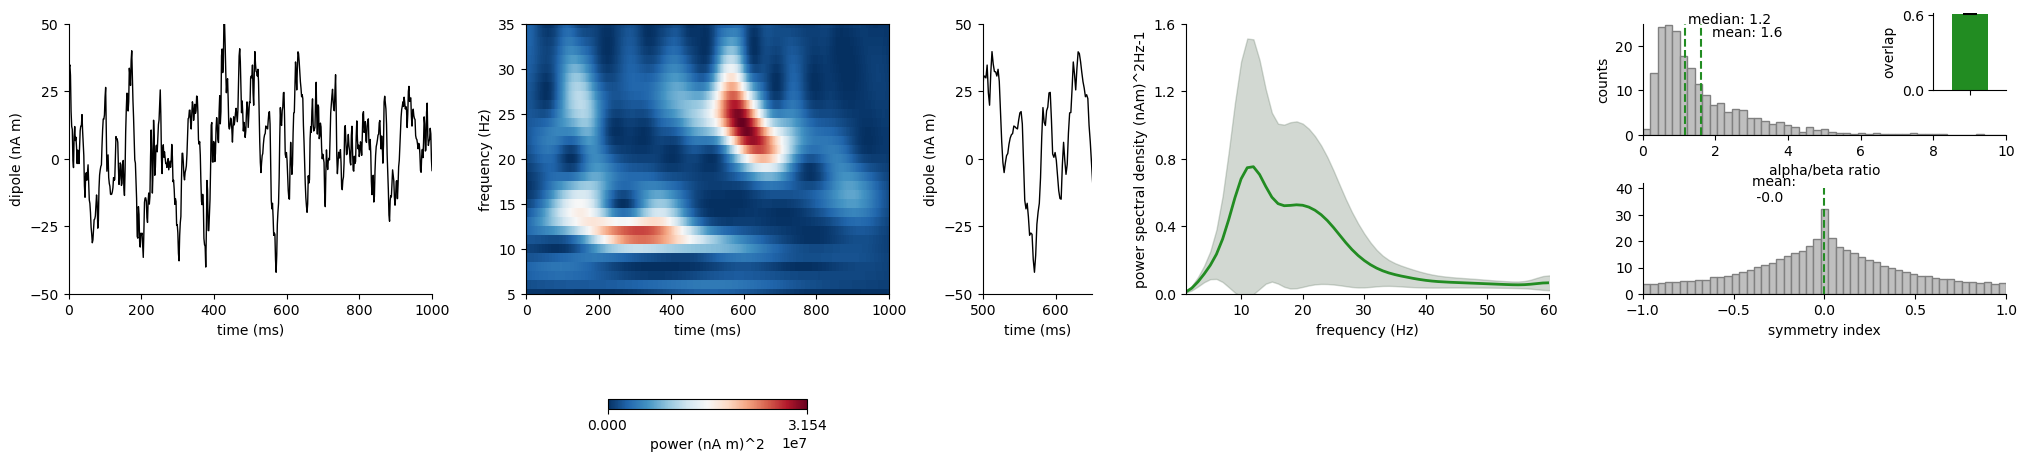

In [14]:
def plot_data():
    """Composite human-MEG figure (green) -> results/.../alpha_beta_data. Reuses the model panel functions."""
    fig = plt.figure(figsize=(25, 5))
    gs = GridSpec(3, 5, width_ratios=[1, 1, 0.3, 1, 1], height_ratios=[0.5, 0.5, 0.3], wspace=.3, hspace=0.5)
    ax0 = fig.add_subplot(gs[:2, 0]); ax1 = fig.add_subplot(gs[:2, 1]); ax2 = fig.add_subplot(gs[:2, 2])
    ax3 = fig.add_subplot(gs[:2, 3]); ax4 = fig.add_subplot(gs[0, 4]); ax5 = fig.add_subplot(gs[1, 4])
    cax = fig.add_subplot(gs[2, 1])
    color, fill = '#228c22', '#4E664F'
    times = subj1_dpls[0].times * 1000

    plot_dipole(ax0, times, subj1_dpls[90].data['agg'], xlim=(0, 1000), ylim=(-50, 50), yticks=[-50, -25, 0, 25, 50])
    plot_tfr(ax1, subj1_dpls[90], times, cax=cax)
    plot_dipole(ax2, times, subj1_dpls[90].data['agg'], xlim=(500, 650), ylim=(-50, 50), yticks=[-50, -25, 0, 25, 50])
    plot_psd(ax3, f[0], psd_all_subj, color=color, ylim=(0, 1.6), yticks=[0, 0.4, 0.8, 1.2, 1.6], fill_color=fill)
    plot_ab_ratio(ax4, np.concatenate(ab_ratio), np.mean(povl), color=color, ymax=2500, yticks=np.arange(0, 2501, 1000),
                  yticklabels=np.arange(0, 25, 10), overlap_err=np.std(povl), inset_ylim=(0, 0.62),
                  inset_yticks=(0, 0.6), text_y=(2200, 2500))
    plot_symmetry(ax5, np.concatenate(s_idx), color=color, yticks=np.arange(0, 4001, 1000),
                  yticklabels=np.arange(0, 41, 10), text_y=3500, vline_ymax=4000)

    fig.savefig(op.join(pathfig, 'alpha_beta_data.pdf'))
    fig.savefig(op.join(pathfig, 'alpha_beta_data.png'))
    return fig


plot_data()

## Laminar LFP and CSD - not in paper

Re-run a single trial with a laminar electrode array and compute the current-source density (CSD) alongside the LFP traces.

In [ ]:
with open(op.join(out_pth, f'net_delay_{run_idx}.pkl'), 'rb') as fh:
    net = pickle.load(fh)
    
net_single_trl = net.copy()
del net
net_single_trl.set_cell_positions(inplane_distance=30)
depths = list(list(range(-500,2200,100)))
electrode_pos = [(135, 135, dep) for dep in depths]
net_single_trl.add_electrode_array('probe1', electrode_pos)
with MPIBackend(n_procs=n_procs, mpi_cmd='mpiexec'):
    dpl = simulate_dipole(net_single_trl, tstop=1000, n_trials=1, bsl_cor='duecker')
    
lfp = net_single_trl.rec_arrays['probe1'][0].voltages[0]

from hnn_core.extracellular import _get_laminar_z_coords, calculate_csd2d
from scipy.interpolate import RectBivariateSpline
contact_labels, delta = _get_laminar_z_coords(net_single_trl.rec_arrays['probe1'][0].positions)
contact_l_cm = contact_labels[::2]/1000
yticklabels = np.abs(np.round(contact_l_cm-contact_l_cm.max(),1))
yticks = np.linspace(contact_labels[0], contact_labels[-1], len(yticklabels))

csd = calculate_csd2d(lfp, delta=delta)

# create interpolation function
interp_data = RectBivariateSpline(net_single_trl.cell_response.times, contact_labels, csd.T)

# increase number of contacts
new_depths = np.linspace(
    contact_labels[0],
    contact_labels[-1],
    contact_labels[-1] - contact_labels[0],
)
# interpolate
csd_int = interp_data(net_single_trl.cell_response.times, new_depths).T

voltage_offset = 500

trace_offset = np.arange(lfp.shape[0])[:, np.newaxis]* voltage_offset
trace_offset_2d = np.tile(trace_offset, (1, lfp.shape[1]))


yticklabels = np.abs(np.round(contact_l_cm-contact_l_cm.max(),1))
yticks = np.linspace(contact_labels[0], contact_labels[-1], len(yticklabels))

fig, ax = plt.subplots(figsize=(8,4))
im = ax.pcolormesh(net_single_trl.cell_response.times, new_depths, csd_int, cmap='jet', shading="auto", rasterized=True, vmin=-0.015, vmax=0.015)

ax.set_yticks(yticks)
ax.set_yticklabels(yticklabels)
ax.spines['top'].set_visible(False)
ax0tw = ax.twinx()
ax0tw.plot(net_single_trl.cell_response.times, (lfp+trace_offset_2d).T, color='k', linewidth=0.75);
ax0tw.set_yticks(trace_offset[::2].reshape(-1,))                      # make sure that ylims are aligned
ax0tw.set_yticks([])
ax0tw.set_ylim(trace_offset[0], trace_offset[::2][-1])
ax0tw.spines['top'].set_visible(False)
cb = plt.colorbar(im)


/oscar/home/kduecker/oscar-install/hnn-core/hnn_core/parallel_backends.py:1033: UserWarning: Number of requested MPI processes exceeds available cores. Enabling MPI oversubscription automatically.
  warn(


MPI will run 1 trial(s) sequentially by distributing network neurons over 20 processes.
numprocs=20
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Building the NEURON model
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-c